In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
%matplotlib inline

In [2]:
from ev_purchases.data_loader import load_data

In [11]:
%pwd

'c:\\Python Learning\\Learning ML\\EV-Purchases\\notebooks'

In [3]:
df  = load_data(Path("../data/raw/train.csv"))

# Subsidy available

- Check if feature can be derived from other to check if this feature likely enriched or provided via user input

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           668665 non-null  int64  
 1   Age                          668665 non-null  int64  
 2   Annual_Income_USD            668665 non-null  float64
 3   Daily_Commute_km             668665 non-null  float64
 4   Number_of_Cars_Owned         668665 non-null  int64  
 5   Charging_Stations_Near_Home  668665 non-null  int64  
 6   Charging_Stations_Near_Work  668665 non-null  int64  
 7   Environmental_Concern_Level  668665 non-null  float64
 8   Gender                       668665 non-null  str    
 9   City_Type                    668665 non-null  str    
 10  Current_Car_Type             668665 non-null  str    
 11  Home_Charging_Possible       668665 non-null  str    
 12  Subsidy_Available            668665 non-null  str    
 13  Range_Anxi

In [43]:
df['Subsidy_Available'].isna().sum()

np.int64(0)

In [39]:
pd.crosstab(df['City_Type'], df['Subsidy_Available'], normalize='index')

Subsidy_Available,No,Yes
City_Type,,
Rural,0.348693,0.651307
Suburban,0.373174,0.626826
Urban,0.380996,0.619004


<Axes: xlabel='Annual_Income_USD', ylabel='Count'>

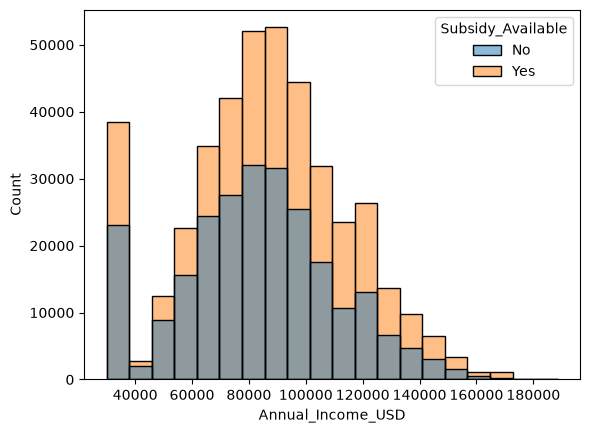

In [42]:
sns.histplot(
    df,
    x='Annual_Income_USD',
    bins=20,
    hue='Subsidy_Available'
)

## Verdict of a Feature

- Subsidy available is not derived from other features
- Use this feature as input

# Charging stations lookup

In [4]:
df.head()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,1,38,30000.0,5.0,1,2,2,4.0,Male,Rural,SUV,Yes,No,Low,No
2,2,26,94389.0,36.8,1,8,15,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,3,66,73580.0,23.7,2,6,9,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,4,54,57898.0,50.8,1,2,3,3.0,Male,Suburban,Hatchback,Yes,No,Low,No


In [46]:
df['City_Type'].unique()

<ArrowStringArray>
['Suburban', 'Rural', 'Urban']
Length: 3, dtype: str

In [48]:
pd.crosstab(
    df['City_Type'],
    df['Charging_Stations_Near_Home'],
    normalize='index'
)

Charging_Stations_Near_Home,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
City_Type,,,,,,,,,,,,,,,
Rural,0.306195,0.314914,0.378842,0.000048,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
Suburban,0.124894,0.114039,0.127658,0.136449,0.126887,0.125129,0.121444,0.123441,0.000031,0.000027,0.000000,0.00000,0.000000,0.000000,0.000000
Urban,0.000024,0.000035,0.075961,0.082933,0.073583,0.072695,0.085353,0.089577,0.071924,0.077389,0.069321,0.08181,0.074807,0.073563,0.071025


In [50]:
pd.crosstab(
    df['City_Type'],
    df['Will_Buy_EV'],
    normalize='index'
)

Will_Buy_EV,No,Yes
City_Type,,
Rural,0.806611,0.193389
Suburban,0.819064,0.180936
Urban,0.838942,0.161058


In [48]:
towns = {
    "Urban":    ["Amperia Central", "Riverside Quarter", "Market Hill", "Canal Side", "Station Row"],
    "Suburban": ["Northfield Park", "Willow Green", "Oakbrook", "Elm Rise", "Brookfield"],
    "Rural":    ["Thornbury Vale", "Hollin Moor", "Ashby Fen", "Little Marsh", "Crowley End"],
}

## Postcode lookup

- 50 postcodes mapped to a city type and town
- Charging stations per postcode sampled from the training distribution of its city type

In [75]:
df['Charging_Stations_Near_Home'].dtype

dtype('int64')

In [55]:
np.sort(df['Charging_Stations_Near_Home'].unique())

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14])

In [15]:
city_home_stations_probabilities = {}
for city in ['Rural', 'Urban', 'Suburban']:
    station_distribution = pd.crosstab(
        df['City_Type'],
        df['Charging_Stations_Near_Home'],
        normalize='index'
    ).loc[f"{city}"].to_dict()

    city_home_stations_probabilities[f"{city}"] = station_distribution

In [16]:
city_home_stations_probabilities['Rural']

{0: 0.30619520418121837,
 1: 0.3149141414548769,
 2: 0.3788422606325061,
 3: 4.8393731398659494e-05,
 4: 0.0,
 5: 0.0,
 6: 0.0,
 7: 0.0,
 8: 0.0,
 9: 0.0,
 10: 0.0,
 11: 0.0,
 12: 0.0,
 13: 0.0,
 14: 0.0}

In [64]:
df.columns

Index(['id', 'Age', 'Annual_Income_USD', 'Daily_Commute_km',
       'Number_of_Cars_Owned', 'Charging_Stations_Near_Home',
       'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Gender',
       'City_Type', 'Current_Car_Type', 'Home_Charging_Possible',
       'Subsidy_Available', 'Range_Anxiety_Level', 'Will_Buy_EV'],
      dtype='str')

In [71]:
from typing import Literal
rng = np.random.default_rng(seed=42)

def generate_station_probability(df: pd.DataFrame, station_type: Literal["Home", "Work"]) -> dict:

    if station_type  not in ['Home', 'Work']:
        raise ValueError(f"station_type only accepts 'Home' or 'Work' got {station_type!r} instead")
    
    city_stations_probabilities = {}

    for city in ['Rural', 'Urban', 'Suburban']:
        station_distribution = pd.crosstab(
            df['City_Type'],
            df[f'Charging_Stations_Near_{station_type}'],
            normalize='index'
        ).loc[f"{city}"].to_dict()

        city_stations_probabilities[f"{city}"] = station_distribution
    return city_stations_probabilities

def random_postcode(rng):
    alphabet = list("ABCDEFGHJKLMNPRSTUWXYZ")
    return str(rng.integers(1,9)) + rng.choice(alphabet) + rng.choice(alphabet) + " " + str(rng.integers(1,9)) + rng.choice(alphabet) +  rng.choice(alphabet) 

def generate_postcode_station_lookup(rng, n:int, station_type: Literal["Home", "Work"]) -> dict:

    if station_type  not in ['Home', 'Work']:
        raise ValueError(f"station_type only accepts 'Home' or 'Work' got {station_type!r} instead")
    
    postcodes_dict = {}
    postcodes = set()
    city_stations_probabilities = generate_station_probability(df, station_type)

    while len(postcodes) < n:
        postcodes.add(random_postcode(rng))

    for p in sorted(postcodes): # it makes loop deterministic due to python set hashing tricks
        city_choice = rng.choice(['Rural', 'Urban', 'Suburban'])
        home_stations = rng.choice(
        a=list(city_stations_probabilities[city_choice].keys()),
        p=list(city_stations_probabilities[city_choice].values())
        )
        postcodes_dict[p] = {'City_Type': str(city_choice), 'Stations': int(home_stations)}

    return postcodes_dict

In [73]:
test = generate_postcode_station_lookup(rng, 50, station_type='Home')

In [77]:
test['1BJ 8SC']['Stations']

7

In [51]:
rng = np.random.default_rng(42)

# Empirical P(Charging_Stations_Near_Home | City_Type) from the training data
station_dist = pd.crosstab(
    df['City_Type'],
    df['Charging_Stations_Near_Home'],
    normalize='index'
)
city_share = df['City_Type'].value_counts(normalize=True)


def random_postcode(rng):
    letters = np.array(list("ABCDEFGHJKLMNPRSTUWXYZ"))
    return (
        "".join(rng.choice(letters, 2)) + str(rng.integers(1, 10))
        + " " + str(rng.integers(1, 10)) + "".join(rng.choice(letters, 2))
    )


def generate_postcodes(n=50):
    postcodes = set()
    while len(postcodes) < n:
        postcodes.add(random_postcode(rng))

    city_types = rng.choice(city_share.index, size=n, p=city_share.values)
    rows = []
    for postcode, city_type in zip(sorted(postcodes), city_types):
        rows.append({
            "Postcode": postcode,
            "City_Type": city_type,
            "Town": rng.choice(towns[city_type]),
            # one draw per postcode, from that city type's training distribution
            "Charging_Stations_Near_Home": rng.choice(
                station_dist.columns, p=station_dist.loc[city_type].values
            ),
        })
    return pd.DataFrame(rows)


postcode_lookup = generate_postcodes(50)
postcode_lookup

,Postcode,City_Type,Town,Charging_Stations_Near_Home
0,BC5 9CL,Rural,Crowley End,2
1,BN8 3PA,Rural,Little Marsh,1
2,BS2 1MZ,Urban,Market Hill,2
3,BT6 6NN,Suburban,Northfield Park,1
4,BU6 4KW,Urban,Riverside Quarter,10
5,CN5 8ZR,Suburban,Northfield Park,0
6,DJ3 3SP,Urban,Riverside Quarter,10
7,DN1 6PB,Suburban,Oakbrook,4
8,DN8 2GY,Suburban,Oakbrook,6
9,EH6 2RC,Suburban,Northfield Park,5
